In [709]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split , cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
import pickle
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score,classification_report

In [710]:
data = pd.read_csv('/content/WA_Fn-UseC_-Telco-Customer-Churn.csv')

In [711]:
data.shape

(7043, 21)

In [712]:
data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [713]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [714]:
data.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [715]:
data['Churn'].value_counts()

,count
Churn,
No,5174
Yes,1869


In [716]:
data.drop('customerID',axis = 1,inplace = True)

In [717]:
data['TotalCharges'] = pd.to_numeric(data['TotalCharges'],errors = 'coerce')


In [718]:
data

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,No
7039,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,No
7040,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,Yes


In [719]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


In [720]:
print(data['TotalCharges'].isnull().sum())

11


In [721]:
data['TotalCharges'].fillna(data['TotalCharges'].median(),inplace=True)

/tmp/ipykernel_3469/4236250119.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data['TotalCharges'].fillna(data['TotalCharges'].median(),inplace=True)


In [722]:
print(data['TotalCharges'].isnull().sum())

0


In [723]:
for col in data.columns:
  print(col, data[col].unique())
  print('-'*50)


gender ['Female' 'Male']
--------------------------------------------------
SeniorCitizen [0 1]
--------------------------------------------------
Partner ['Yes' 'No']
--------------------------------------------------
Dependents ['No' 'Yes']
--------------------------------------------------
tenure [ 1 34  2 45  8 22 10 28 62 13 16 58 49 25 69 52 71 21 12 30 47 72 17 27
  5 46 11 70 63 43 15 60 18 66  9  3 31 50 64 56  7 42 35 48 29 65 38 68
 32 55 37 36 41  6  4 33 67 23 57 61 14 20 53 40 59 24 44 19 54 51 26  0
 39]
--------------------------------------------------
PhoneService ['No' 'Yes']
--------------------------------------------------
MultipleLines ['No phone service' 'No' 'Yes']
--------------------------------------------------
InternetService ['DSL' 'Fiber optic' 'No']
--------------------------------------------------
OnlineSecurity ['No' 'Yes' 'No internet service']
--------------------------------------------------
OnlineBackup ['Yes' 'No' 'No internet service']
-------

In [724]:
def plot_hist(df,column_name):
  plt.figure(figsize=(10,6))
  sns.histplot(df[column_name],kde=True)
  plt.title(f'Distribution of {column_name}')

  col_mean = df[column_name].mean()
  col_median = df[column_name].median()
  plt.axvline(col_mean,color='red',linestyle='dashed',linewidth=2,label='Mean')
  plt.axvline(col_median,color='green',linestyle='dashed',linewidth=2,label='Median')
  plt.legend()
  plt.show()

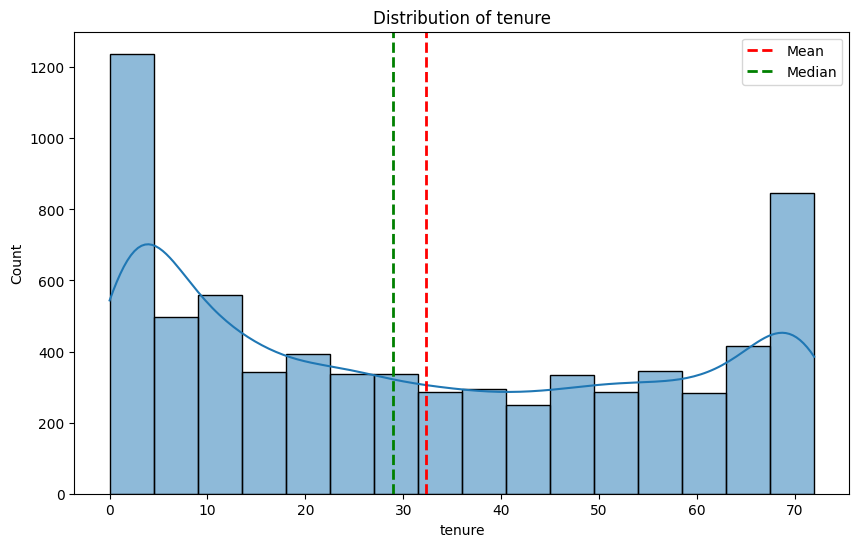

In [725]:
plot_hist(data,'tenure')

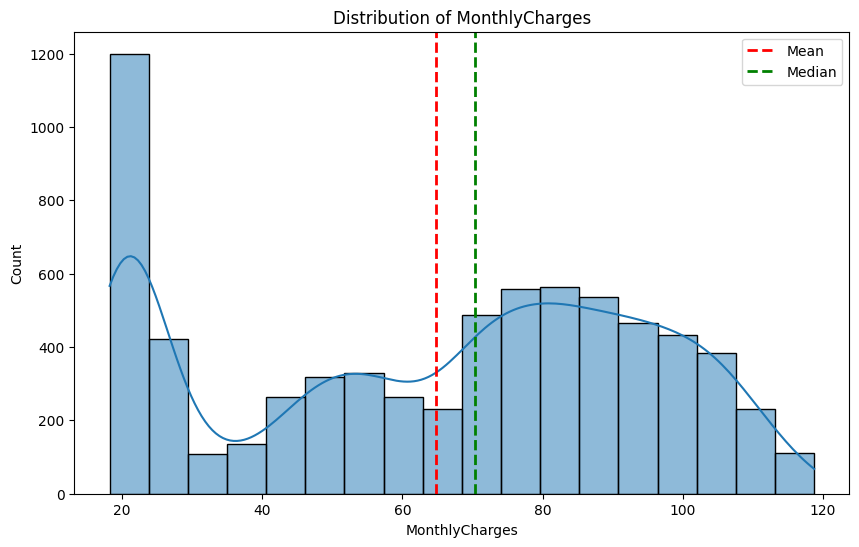

In [726]:
plot_hist(data,'MonthlyCharges')

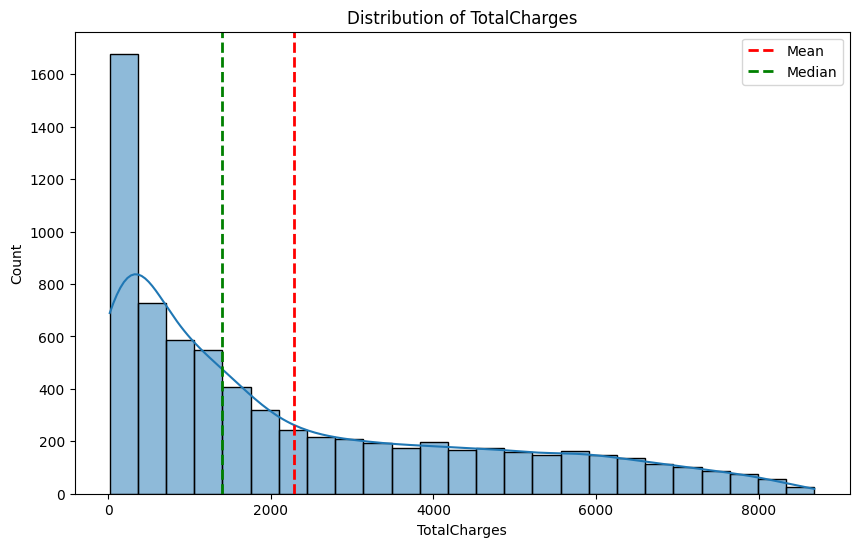

In [727]:
plot_hist(data,'TotalCharges')

#for checking outliers

In [728]:
def plot_boxplot(df,column_name):
  plt.figure(figsize=(10,6))
  sns.boxplot(df[column_name])
  plt.title(f'Distribution of {column_name}')
  plt.ylabel(column_name)
  plt.show()

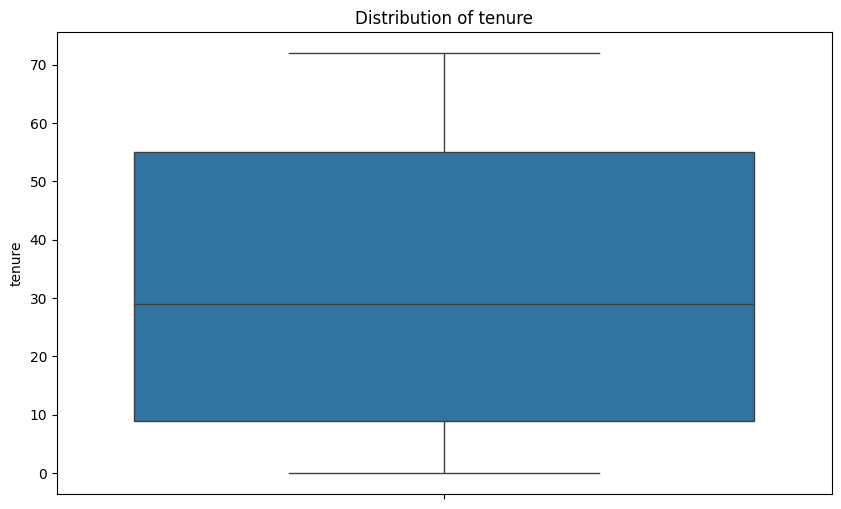

In [729]:
plot_boxplot(data,'tenure')

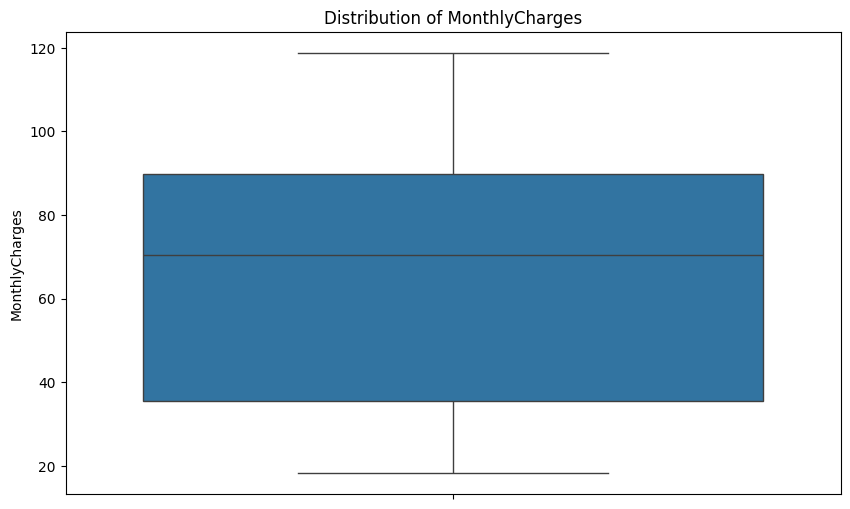

In [730]:
plot_boxplot(data,'MonthlyCharges')

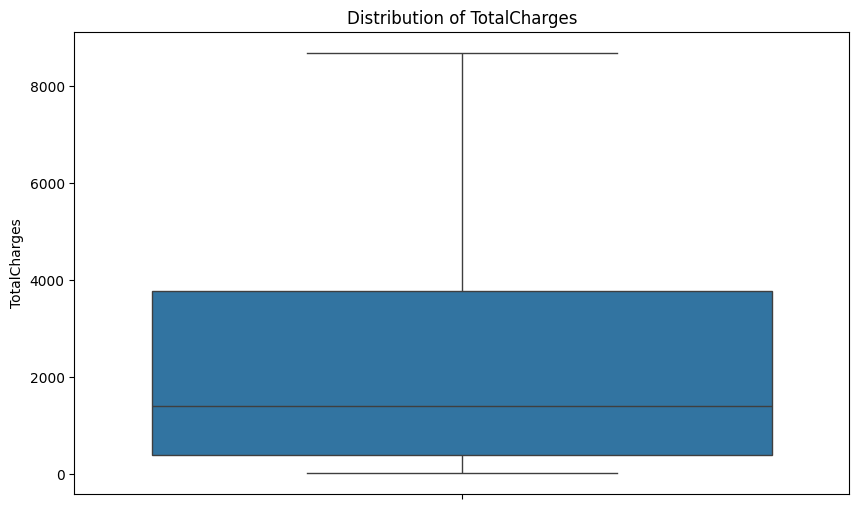

In [731]:
plot_boxplot(data,'TotalCharges')

# totalcharges and tenure - highly correlated

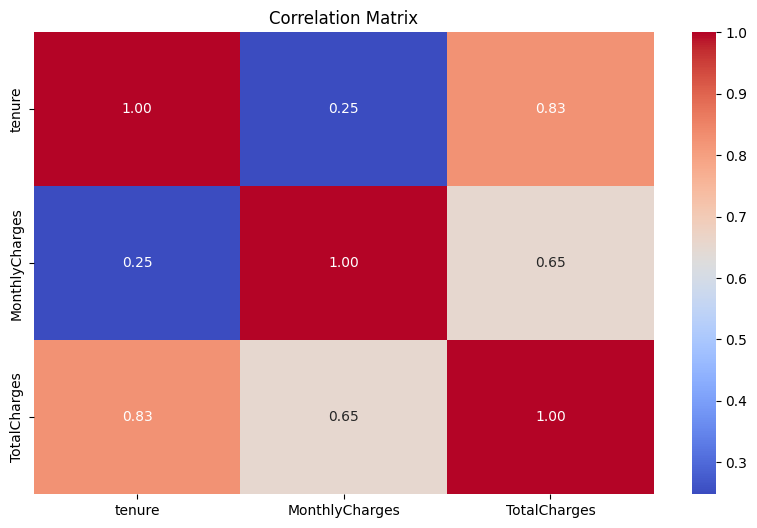

In [732]:
plt.figure(figsize=(10,6))
sns.heatmap(data[['tenure','MonthlyCharges','TotalCharges']].corr(),annot = True,cmap='coolwarm',fmt='.2f')
plt.title('Correlation Matrix')
plt.show()

In [733]:
data.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [734]:
data['Churn'] = data['Churn'].replace({"Yes":1,"No":0})

/tmp/ipykernel_3469/3445277996.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data['Churn'] = data['Churn'].replace({"Yes":1,"No":0})


In [735]:
data.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [736]:
data.tail()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,0
7039,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,0
7040,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,0
7041,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,1
7042,Male,0,No,No,66,Yes,No,Fiber optic,Yes,No,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.50,0


In [737]:
object_col = data.select_dtypes(include = "object").columns

In [738]:
print(object_col)

Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='object')


In [739]:
encoders = {}
for column in object_col:
  le = LabelEncoder()
  data[column] = le.fit_transform(data[column])
  encoders[column] = le
  #save to use it later for predict with same label encoder
  with open("encoders.pkl","wb") as file:
    pickle.dump(encoders,file)

In [740]:
encoders

{'gender': LabelEncoder(),
 'Partner': LabelEncoder(),
 'Dependents': LabelEncoder(),
 'PhoneService': LabelEncoder(),
 'MultipleLines': LabelEncoder(),
 'InternetService': LabelEncoder(),
 'OnlineSecurity': LabelEncoder(),
 'OnlineBackup': LabelEncoder(),
 'DeviceProtection': LabelEncoder(),
 'TechSupport': LabelEncoder(),
 'StreamingTV': LabelEncoder(),
 'StreamingMovies': LabelEncoder(),
 'Contract': LabelEncoder(),
 'PaperlessBilling': LabelEncoder(),
 'PaymentMethod': LabelEncoder()}

In [741]:
data.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,0,1,0,1,0,1,0,0,2,0,0,0,0,0,1,2,29.85,29.85,0
1,1,0,0,0,34,1,0,0,2,0,2,0,0,0,1,0,3,56.95,1889.50,0
2,1,0,0,0,2,1,0,0,2,2,0,0,0,0,0,1,3,53.85,108.15,1
3,1,0,0,0,45,0,1,0,2,0,2,2,0,0,1,0,0,42.30,1840.75,0
4,0,0,0,0,2,1,0,1,0,0,0,0,0,0,0,1,2,70.70,151.65,1


In [742]:
x = data.drop('Churn',axis = 1)
y = data['Churn']
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size = 0.2,random_state = 2)

In [743]:
scaler = StandardScaler()
x_train[['tenure','MonthlyCharges','TotalCharges']] = scaler.fit_transform(x_train[['tenure','MonthlyCharges','TotalCharges']])
x_test[['tenure','MonthlyCharges','TotalCharges']] = scaler.transform(x_test[['tenure','MonthlyCharges','TotalCharges']])

with open("scaler.pkl", "wb") as file:
    pickle.dump(scaler, file)

In [744]:
print(y_train.value_counts())

Churn
0    4113
1    1521
Name: count, dtype: int64


In [745]:
smote = SMOTE(random_state=2)
x_train_smote,y_train_smote = smote.fit_resample(x_train,y_train)

In [746]:
print(y_train_smote.value_counts())


Churn
1    4113
0    4113
Name: count, dtype: int64


Model Traininig

In [747]:
def evaluate_model(model, X_test, y_test):

    y_pred = model.predict(X_test)

    print("Accuracy :", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred))
    print("Recall   :", recall_score(y_test, y_pred))
    print("F1 Score :", f1_score(y_test, y_pred))

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

without

In [748]:
lr = LogisticRegression()
lr.fit(x_train_smote,y_train_smote)

LogisticRegression()

In [749]:
evaluate_model(lr, x_test, y_test)

Accuracy : 0.7501774308019872
Precision: 0.49625468164794007
Recall   : 0.7614942528735632
F1 Score : 0.6009070294784581

Confusion Matrix:
[[792 269]
 [ 83 265]]


In [750]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=2),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=2
    ),
    "SVM": SVC(),
    "Naive Bayes": GaussianNB(),
    "XGBoost": XGBClassifier(
        random_state=2
    )
}

cv_scores = {}

for model_name, model in models.items():

    print(f"\n{model_name}")

    scores = cross_val_score(
        model,
        x_train_smote,
        y_train_smote,
        cv=5,
        scoring="accuracy"
    )

    cv_scores[model_name] = scores

    print("CV Scores:", scores)
    print("Mean CV Accuracy:", scores.mean())


Logistic Regression
CV Scores: [0.74483597 0.77142857 0.79452888 0.8006079  0.80729483]
Mean CV Accuracy: 0.7837392296697898

Decision Tree
CV Scores: [0.7126367  0.73495441 0.79878419 0.79878419 0.80121581]
Mean CV Accuracy: 0.7692750593683868

Random Forest
CV Scores: [0.78797084 0.80182371 0.86990881 0.8662614  0.86382979]
Mean CV Accuracy: 0.8379589093205597

SVM
CV Scores: [0.76245443 0.78905775 0.8218845  0.8224924  0.82006079]
Mean CV Accuracy: 0.8031899751446815

Naive Bayes
CV Scores: [0.72296476 0.77507599 0.77507599 0.79452888 0.77993921]
Mean CV Accuracy: 0.7695169647704485

XGBoost
CV Scores: [0.74969623 0.78237082 0.87051672 0.86322188 0.85896657]
Mean CV Accuracy: 0.8249544442269553


In [751]:
# rf = RandomForestClassifier(
#     n_estimators=100,
#     random_state=2
# )

# rf.fit(x_train_smote, y_train_smote)

# evaluate_model(rf, x_test, y_test)


# RandomForestClassifier: rf

# RandomForestClassifier with 100 items

# Accuracy : 0.7757274662881476
# Precision: 0.54
# Recall   : 0.6206896551724138
# F1 Score : 0.5775401069518716

# Confusion Matrix:
# [[877 184]
#  [132 216]]

In [752]:
# svm = SVC()
# svm.fit(x_train_smote, y_train_smote)
# evaluate_model(svm, x_test, y_test)
# Accuracy : 0.7508871540099361
# Precision: 0.49700598802395207
# Recall   : 0.7155172413793104
# F1 Score : 0.5865724381625441

# Confusion Matrix:
# [[809 252]
#  [ 99 249]]

In [753]:
# nb = GaussianNB()
# nb.fit(x_train_smote, y_train_smote)
# evaluate_model(nb, x_test, y_test)
# Accuracy : 0.7295954577714692
# Precision: 0.46938775510204084
# Recall   : 0.7270114942528736
# F1 Score : 0.5704622322435174

# Confusion Matrix:
# [[775 286]
#  [ 95 253]]

In [754]:
# dt = DecisionTreeClassifier(random_state=2)

# dt.fit(x_train_smote, y_train_smote)

# evaluate_model(dt, x_test, y_test)
# Accuracy : 0.7331440738112136
# Precision: 0.4692982456140351
# Recall   : 0.6149425287356322
# F1 Score : 0.5323383084577115

# Confusion Matrix:
# [[819 242]
#  [134 214]]

In [755]:
# xgb = XGBClassifier(
#     random_state=2
# )

# xgb.fit(x_train_smote, y_train_smote)

# evaluate_model(xgb, x_test, y_test)
# Accuracy : 0.7700496806245565
# Precision: 0.53
# Recall   : 0.6091954022988506
# F1 Score : 0.5668449197860963

# Confusion Matrix:
# [[873 188]
#  [136 212]]

In [756]:
lr = LogisticRegression(max_iter=1000)
lr.fit(x_train_smote,y_train_smote)
evaluate_model(lr, x_test, y_test)

Accuracy : 0.7501774308019872
Precision: 0.49625468164794007
Recall   : 0.7614942528735632
F1 Score : 0.6009070294784581

Confusion Matrix:
[[792 269]
 [ 83 265]]


In [757]:
with open("churn_model.pkl", "wb") as file:
    pickle.dump(lr, file)

print("Model saved successfully!")

Model saved successfully!


In [758]:
x_train_smote

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,0,0,0,0,-0.705310,1,0,1,0,2,2,0,2,2,0,1,2,1.206336,-0.364304
1,0,0,0,0,0.108051,1,0,0,0,0,2,0,0,2,0,1,2,-0.095544,-0.083296
2,1,0,1,1,1.612768,0,1,0,2,0,2,2,2,2,2,0,0,-0.133785,0.995674
3,1,0,1,1,0.148719,0,1,0,2,0,2,2,2,2,1,0,1,-0.142099,-0.022397
4,0,0,1,0,1.328092,1,2,1,0,2,2,2,2,2,1,1,1,1.432461,2.126064
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8221,0,0,0,0,0.539127,1,2,0,2,2,0,0,0,0,0,0,1,-0.176831,0.192362
8222,1,0,0,0,-1.271306,1,0,0,0,0,2,0,0,0,0,1,2,-0.510238,-0.981293
8223,0,0,0,0,-1.166568,1,0,1,0,0,0,0,0,0,0,0,0,0.190548,-0.894878
8224,1,0,0,0,-1.233994,1,0,0,0,0,0,0,0,0,0,0,3,-0.636365,-0.969700
